In [22]:
import sys
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from collections import Counter

root = Path.cwd()
if not (root / "src").exists():   # notebook is inside a subfolder
    root = root.parent
sys.path.insert(0, str(root / "src"))

from data.dataset import load_dataset, get_image, DEFAULT_ROOT

data = load_dataset(DEFAULT_ROOT)

recs = data["train"]
boxes = np.concatenate([r.boxes for r in recs])
img_w = np.concatenate([np.full(len(r.boxes), r.width) for r in recs])
img_h = np.concatenate([np.full(len(r.boxes), r.height) for r in recs])
bw, bh = boxes[:, 2] - boxes[:, 0], boxes[:, 3] - boxes[:, 1]   # box width/height in pixels


In [23]:
# 1. Counts
for split, recs in data.items():
    n = [len(r.boxes) for r in recs]
    print(split, len(recs), "images,", sum(n), "boxes,", n.count(0), "empty")


train 1369 images, 8663 boxes, 154 empty
val 291 images, 1843 boxes, 33 empty
test 240 images, 1518 boxes, 27 empty


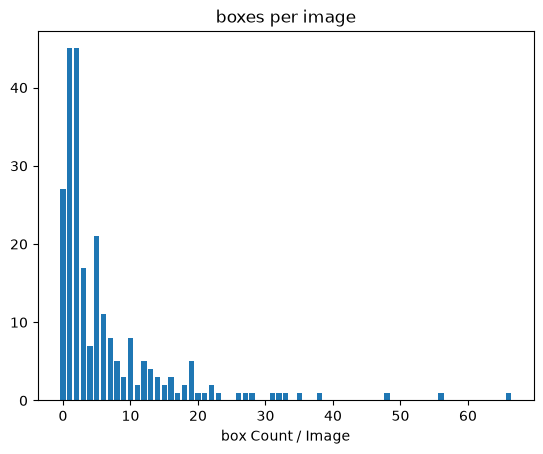

average: 6.325 | most in one image: 66


In [25]:

# 2. Birds per image
counts = [len(r.boxes) for r in recs]
c = np.bincount(counts)
plt.bar(range(len(c)), c)
plt.xlabel("box Count / Image")
plt.title("boxes per image")
plt.show()
print("average:", np.mean(counts), "| most in one image:", max(counts))


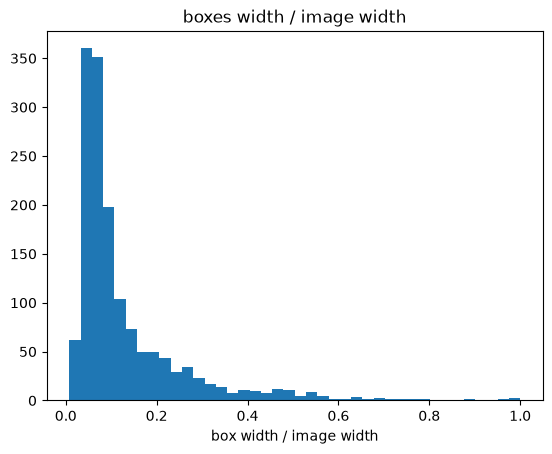

birds under 5% of image width: 0.23213667320789566


In [26]:

# 3. Bird size (as a fraction of image width)
w = np.concatenate([(r.boxes[:, 2] - r.boxes[:, 0]) / r.width for r in recs])
plt.hist(w, bins=40)
plt.xlabel("box width / image width")
plt.title("boxes width / image width")

plt.show()
print("birds under 5% of image width:", (bw / img_w < 0.05).mean())


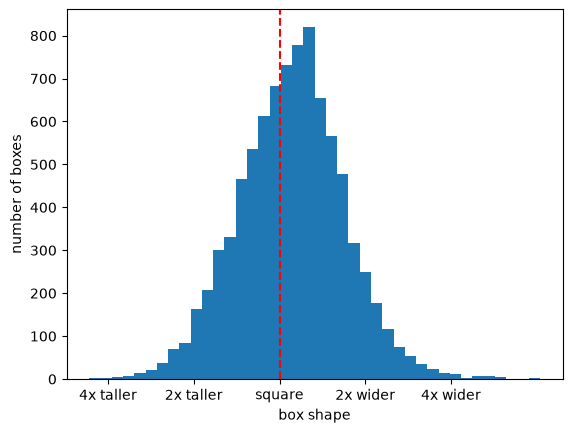

In [27]:

# 4. Box shape 
r = np.log2(bw / bh)                  # 0 = square, +1 = twice as wide, -1 = twice as tall
plt.hist(r, bins=40)
plt.axvline(0, color="red", linestyle="--")   # square boxes
plt.xticks([-2, -1, 0, 1, 2], ["4x taller", "2x taller", "square", "2x wider", "4x wider"])
plt.xlabel("box shape")
plt.ylabel("number of boxes")
plt.show()


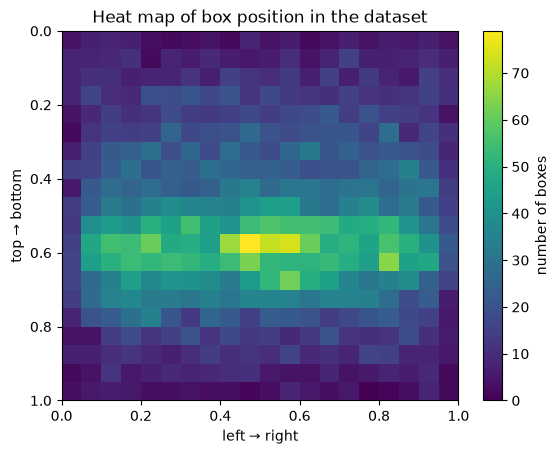

In [28]:

# 5. Bird locations
cx = (boxes[:, 0] + boxes[:, 2]) / 2 / img_w   # 0 = left edge, 1 = right edge
cy = (boxes[:, 1] + boxes[:, 3]) / 2 / img_h   # 0 = top, 1 = bottom
plt.hist2d(cx, cy, bins=20, range=[[0, 1], [0, 1]])
plt.gca().invert_yaxis()                       # so the top of the image is at the top
plt.colorbar(label="number of boxes")
plt.xlabel("left → right")
plt.ylabel("top → bottom")
plt.title("Heat map of box position in the dataset")
plt.show()


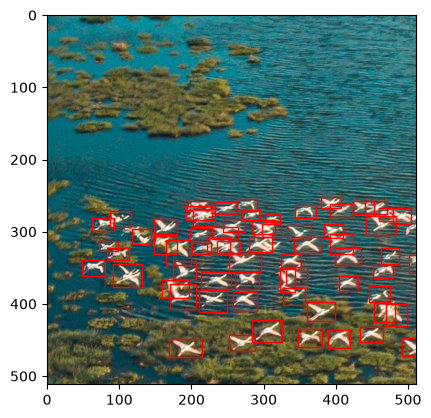

In [31]:

# 6. Draw boxes on one image
r = recs[np.argmax(counts)]
fig, ax = plt.subplots()
ax.imshow(get_image(r))
for x1, y1, x2, y2 in r.boxes:
    ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, color="red"))
plt.show()